# Analyse non supervisée et génération de labels faibles

**Projet ForestFireDetection** – Détection précoce de feux de forêt (fumée / feu)
Objectifs :
1. Simuler un **faible étiquetage** : seuls 5 % des images du train gardent leurs vrais labels.
2. Réduire la dimension des features ResNet50 (**standardisation → PCA → UMAP**).
3. Comparer plusieurs méthodes de clustering (**K-Means, DBSCAN, HDBSCAN**).
4. Attribuer des **labels faibles** (fumée oui/non, feu oui/non) aux images non labellisées.

Entrées : features et métadonnées produites par `preprocessing_feature_extraction.ipynb`.

**Règle anti-fuite** : tout ce qui apprend des données (scaler, PCA, UMAP, clustering) est ajusté sur le
**train uniquement**. Val et test ne sont pas utilisés ici.

## 1. Imports

In [ ]:
import sys
import time
import warnings
from pathlib import Path

# Avertissement d'affichage de tqdm (barre de progression), sans effet sur les calculs
warnings.filterwarnings("ignore", message="IProgress not found")

# Ajout de la racine du projet au chemin Python pour importer src/
ROOT = Path.cwd().resolve()
sys.path.append(str(ROOT.parent if ROOT.name == "notebooks" else ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import adjusted_rand_score, silhouette_score, precision_recall_fscore_support
import umap
import mlflow

## 2. Configuration

In [ ]:
from src.config import (
    FEATURES_PATH, FEATURES_META_PATH, WEAK_LABELS_PATH, CLUSTERING_COMPARISON_PATH,
    RESULTS_DIR, CATEGORY_ORDER, RANDOM_STATE, LABELED_FRACTION,
)

# Paramètres propres à ce notebook
PCA_N_COMPONENTS = 950       # nombre de composantes PCA (≈ 90 % de variance, cf. courbe section 5)
UMAP_PARAMS = dict(          # réglages recommandés par la doc UMAP pour le clustering
    n_neighbors=30,          # plus grand que le défaut (15) : structure moins fragmentée
    min_dist=0.0,            # points regroupés de façon dense (utile au clustering)
    n_components=10,         # clustering en 10D ; la 2D sert uniquement à la visualisation
    random_state=RANDOM_STATE,
    n_jobs=1,                # imposé par random_state (reproductibilité), explicite pour éviter l'avertissement
    compatibility_layout=True,   # comportement actuel d'umap-learn 0.6 conservé (le défaut changera)
)
SELECTED = ("K-Means", "K=64")   # réglage retenu (justifié section 9)
TASKS = ["has_smoke", "has_fire"]

### Suivi des expériences avec MLflow

- Un **run parent** pour l'ensemble de l'analyse : paramètres (labels, PCA, UMAP), qualité finale des labels
  faibles, figures et CSV en artefacts.
- Un **run enfant par réglage de clustering** : paramètres, F1 leave-one-out, ARI, taux de bruit.

Interface web : `uv run mlflow server --port 5000` depuis la racine du projet, puis http://localhost:5000.

In [ ]:
from src.tracking import setup_mlflow

setup_mlflow("unsupervised_analysis")
parent_run = mlflow.start_run(run_name="clustering_weak_labels")   # fermé à la fin du notebook
mlflow.log_params({
    "features": "resnet50_imagenet1k_v2",
    "labeled_fraction": LABELED_FRACTION,
    "pca_n_components": PCA_N_COMPONENTS,
    **{f"umap_{k}": v for k, v in UMAP_PARAMS.items()},
    "random_state": RANDOM_STATE,
})

2026/11/13 13:49:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/13 13:49:14 INFO mlflow.store.db.utils: Updating database tables


MLflow : expérience « unsupervised_analysis » | base : sqlite:///C:/Users/faiza/Formation_IA/ForestFireDetection/mlflow.db


In [ ]:
# Couleurs fixes des catégories (identiques à l'exploration)
CATEGORY_COLORS = {"smoke_only": "#2a78d6", "fire_only": "#eb6834",
                   "fire_and_smoke": "#1baf7a", "none": "#eda100"}

## 3. Chargement des features et du découpage figé

In [ ]:
features = np.load(FEATURES_PATH)
meta = pd.read_csv(FEATURES_META_PATH)
assert len(features) == len(meta)       # une ligne de métadonnées par vecteur

# Seul le train est utilisé dans ce notebook
train_mask = (meta["final_split"] == "train").to_numpy()
X_train = features[train_mask]
df_train = meta[train_mask].reset_index(drop=True)
print(f"Features : {features.shape} | train : {X_train.shape}")

Features : (21527, 2048) | train : (13773, 2048)


## 4. Simulation du faible étiquetage

On tire **5 % du train** qui gardent leurs vrais labels, en respectant la proportion des 4 catégories.
Les 95 % restants sont traités comme **non labellisés** : leurs vrais labels ne servent **qu'à mesurer**
la qualité des labels faibles, jamais à choisir une méthode ou un paramètre.

In [ ]:
labeled_ids, _ = train_test_split(
    df_train["image_id"], train_size=LABELED_FRACTION,
    stratify=df_train["category"], random_state=RANDOM_STATE,
)
df_train["is_labeled"] = df_train["image_id"].isin(set(labeled_ids))
lab_mask = df_train["is_labeled"].to_numpy()

print(f"Labellisées     : {lab_mask.sum()} ({lab_mask.mean():.1%} du train)")
print(f"Non labellisées : {(~lab_mask).sum()}")
display((pd.crosstab(df_train["category"], df_train["is_labeled"], normalize="columns") * 100)
          .reindex(CATEGORY_ORDER).round(1).rename(columns={True: "labellisées (%)", False: "non labellisées (%)"}))

Labellisées     : 688 (5.0% du train)
Non labellisées : 13085


is_labeled,non labellisées (%),labellisées (%)
category,,
smoke_only,27.2,27.2
fire_only,5.4,5.5
fire_and_smoke,21.9,21.8
none,45.5,45.5


## 5. Standardisation puis PCA

- **StandardScaler** : chaque feature centrée-réduite (ajusté sur le train).
- **PCA** : **950 composantes**, choisies à partir de la courbe de variance expliquée (≈ 90 % de la variance).

80% de variance : 543 composantes
90% de variance : 933 composantes
95% de variance : 1273 composantes
150 composantes : 56.9% de variance
200 composantes : 61.7% de variance
950 composantes : 90.3% de variance


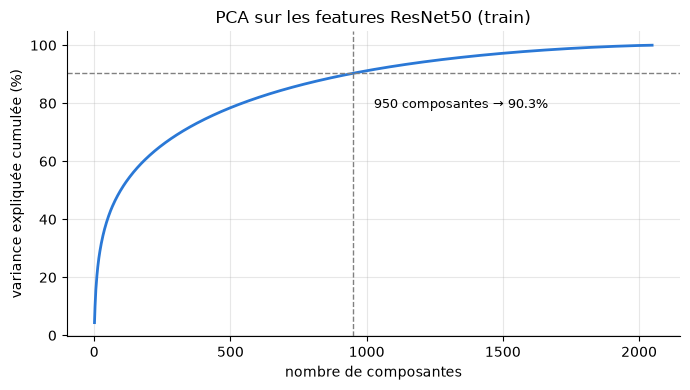

In [ ]:
scaler = StandardScaler().fit(X_train)
X_scaled = scaler.transform(X_train)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = PCA_N_COMPONENTS
for target in [0.80, 0.90, 0.95]:
    print(f"{target:.0%} de variance : {int(np.searchsorted(cum_var, target) + 1)} composantes")
for n in [150, 200, PCA_N_COMPONENTS]:
    print(f"{n} composantes : {cum_var[n - 1]:.1%} de variance")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum_var) + 1), cum_var * 100, color="#2a78d6", linewidth=2)
ax.axhline(cum_var[n_components - 1] * 100, color="gray", linestyle="--", linewidth=1)
ax.axvline(n_components, color="gray", linestyle="--", linewidth=1)
ax.annotate(f"{n_components} composantes → {cum_var[n_components - 1]:.1%}", (n_components, cum_var[n_components - 1] * 100),
            xytext=(15, -25), textcoords="offset points", fontsize=9)
ax.set_xlabel("nombre de composantes")
ax.set_ylabel("variance expliquée cumulée (%)")
ax.set_title("PCA sur les features ResNet50 (train)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_variance.png", dpi=100)
plt.show()

In [ ]:
pca = PCA(n_components=n_components, random_state=RANDOM_STATE).fit(X_scaled)
X_pca = pca.transform(X_scaled)
print(f"PCA : 2048 → {n_components} composantes ({pca.explained_variance_ratio_.sum():.1%} de variance)")
mlflow.log_metric("pca_explained_variance", pca.explained_variance_ratio_.sum())

PCA : 2048 → 950 composantes (90.1% de variance)


## 6. UMAP

Réglages issus de la [doc UMAP sur le clustering](https://umap-learn.readthedocs.io/en/latest/clustering.html) :
`n_neighbors=30`, `min_dist=0`, et **10 dimensions** pour le clustering (le P7 clusterisait en 2D).
La doc prévient qu'UMAP « does not completely preserve density » et peut créer de fausses séparations :
les clusters doivent donc être validés (section 9).

Une seconde projection en **2D** sert uniquement aux graphiques.

In [ ]:
t0 = time.time()
X_umap = umap.UMAP(**UMAP_PARAMS).fit_transform(X_pca)
print(f"UMAP {UMAP_PARAMS['n_components']}D : {X_umap.shape} en {time.time() - t0:.0f} s")

t0 = time.time()
X_umap2 = umap.UMAP(**{**UMAP_PARAMS, "n_components": 2, "min_dist": 0.1}).fit_transform(X_pca)
print(f"UMAP 2D (visualisation) : {X_umap2.shape} en {time.time() - t0:.0f} s")

UMAP 10D : (13773, 10) en 31 s
UMAP 2D (visualisation) : (13773, 2) en 8 s


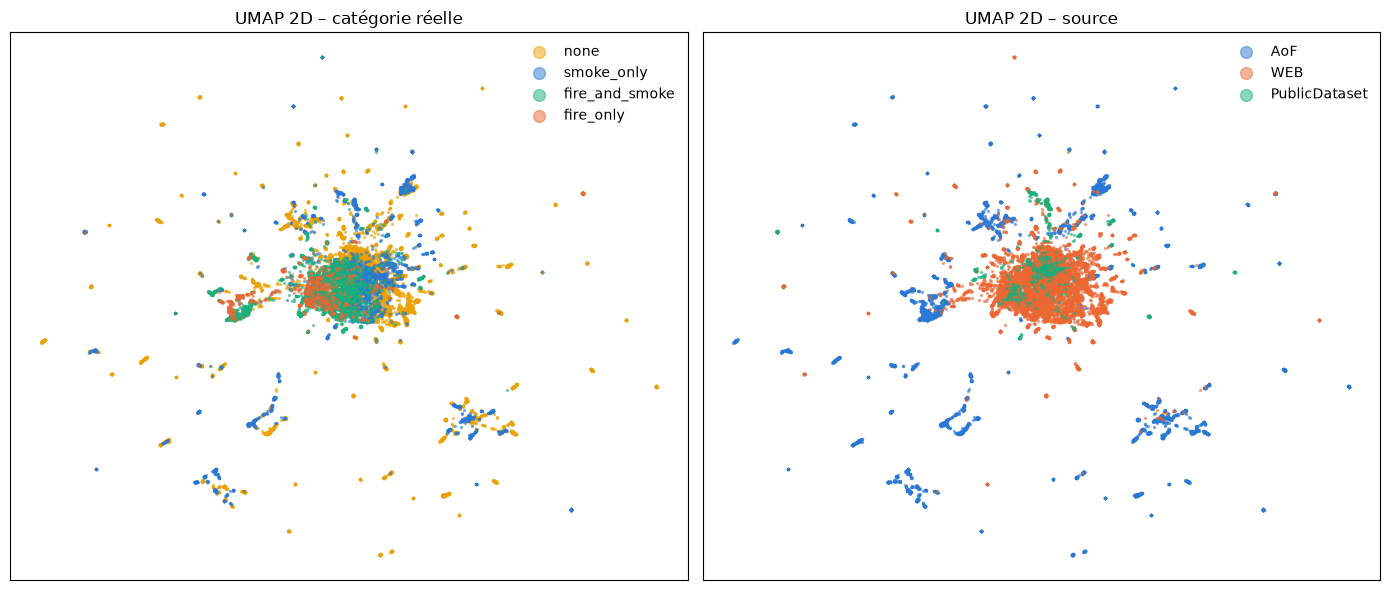

In [ ]:
# Projection 2D colorée par catégorie réelle puis par source
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for cat in ["none", "smoke_only", "fire_and_smoke", "fire_only"]:   # catégories rares tracées en dernier
    m = (df_train["category"] == cat).to_numpy()
    axes[0].scatter(X_umap2[m, 0], X_umap2[m, 1], s=2, alpha=0.5, color=CATEGORY_COLORS[cat], label=cat)
axes[0].set_title("UMAP 2D – catégorie réelle")
source_colors = {"AoF": "#2a78d6", "WEB": "#eb6834", "PublicDataset": "#1baf7a"}
for src, color in source_colors.items():
    m = (df_train["source"] == src).to_numpy()
    axes[1].scatter(X_umap2[m, 0], X_umap2[m, 1], s=2, alpha=0.5, color=color, label=src)
axes[1].set_title("UMAP 2D – source")
for ax in axes:
    ax.legend(markerscale=6, frameon=False)
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.savefig(RESULTS_DIR / "umap_train.png", dpi=100)
plt.show()

## 7. Attribution des labels faibles (mapping cluster → label)

Comme dans le P7, chaque cluster reçoit le **label majoritaire des images labellisées qu'il contient**,
pour chaque tâche (fumée, feu). En cas d'égalité : positif, par précaution (rater un feu coûte plus cher
qu'une fausse alerte).

Les images **sans vote** ne reçoivent **pas** de label faible et ne serviront pas à l'entraînement :
- les points de **bruit** (DBSCAN / HDBSCAN, label -1) ;
- les images d'un cluster qui ne contient **aucune** image labellisée.

**Évaluation honnête** : pour une image labellisée, son label faible est calculé **sans son propre vote**
(leave-one-out). Les scores de comparaison n'utilisent que les images labellisées.

Le code est dans `src/weak_labels.py` pour être couvert par les tests unitaires (`tests/test_weak_labels.py`).

In [ ]:
# Fonctions définies dans src/weak_labels.py (testées par tests/test_weak_labels.py)
from src.weak_labels import assign_weak_labels, score_tasks

y_all = df_train[TASKS].to_numpy()        # vrais labels (servent seulement à l'évaluation)
y_lab = y_all[lab_mask]

## 8. Comparaison des méthodes de clustering

Pour chaque méthode et chaque réglage, calculés **uniquement avec les images labellisées** :
- nombre de clusters, part de bruit, **ARI** (accord avec les catégories réelles, comme dans le P7) ;
- **couverture** : part des images qui reçoivent un label faible, globalement et parmi les images de feu ;
- **F1 leave-one-out** des labels faibles, calculé sur les images labellisées couvertes.

K-Means avec **K = 4** correspond à l'idée « un cluster par catégorie » (none, smoke_only, fire_only,
fire_and_smoke) ; des K plus grands testent l'idée « plusieurs clusters par catégorie ». Limite haute : avec
688 images labellisées, K = 128 laisse en moyenne ~5 images labellisées par cluster pour voter.

In [ ]:
def evaluate_partition(name, params, clusters, silhouette=np.nan):
    """Résumé d'une partition, calculé uniquement avec les images labellisées."""
    weak, has_vote = assign_weak_labels(clusters, lab_mask, y_lab)
    cov = has_vote[lab_mask]                         # couverture des images labellisées
    fire_lab = y_lab[:, 1] == 1
    row = {"methode": name, "parametres": params,
           "n_clusters": len(set(clusters) - {-1}),
           "bruit (%)": 100 * (clusters == -1).mean(),
           "couverture (%)": 100 * cov.mean(),
           "couverture feu (%)": 100 * cov[fire_lab].mean(),
           "ARI (labellisées)": adjusted_rand_score(df_train.loc[lab_mask, "category"], clusters[lab_mask]),
           "silhouette": silhouette}
    row.update(score_tasks(y_lab[cov], weak[lab_mask][cov]))

    # Run MLflow enfant : un réglage = un run (rattaché au run parent)
    with mlflow.start_run(run_name=f"{name} | {params}", nested=True):
        mlflow.log_params({"method": name, "settings": params})
        mlflow.log_metrics({
            "n_clusters": row["n_clusters"], "noise_pct": row["bruit (%)"],
            "coverage_pct": row["couverture (%)"], "fire_coverage_pct": row["couverture feu (%)"],
            "ari_labeled": row["ARI (labellisées)"],
            "smoke_f1_loo": row["has_smoke_f1"], "fire_f1_loo": row["has_fire_f1"], "f1_mean_loo": row["f1_mean"],
            **({"silhouette": silhouette} if not np.isnan(silhouette) else {}),
        })
    return row


results, partitions = [], {}

# K-Means : K = 4 (une catégorie par cluster) puis davantage de clusters (pas de bruit)
for k in [4, 8, 16, 32, 64, 128]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_umap)
    sil = silhouette_score(X_umap, labels, sample_size=5000, random_state=RANDOM_STATE)
    results.append(evaluate_partition("K-Means", f"K={k}", labels, sil))
    partitions[("K-Means", f"K={k}")] = labels

# DBSCAN : min_samples=10, eps = quantiles 50 / 75 / 90 % des distances au 10e voisin (échelle de l'espace UMAP)
for min_samples in [10]:
    kdist = NearestNeighbors(n_neighbors=min_samples).fit(X_umap).kneighbors(X_umap)[0][:, -1]
    for q in [0.50, 0.75, 0.90]:
        eps = float(np.quantile(kdist, q))
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_umap)
        params = f"min_samples={min_samples}, eps={eps:.3f} (q{int(q * 100)})"
        results.append(evaluate_partition("DBSCAN", params, labels))
        partitions[("DBSCAN", params)] = labels

# HDBSCAN : taille minimale de cluster
for min_cluster_size in [25, 50, 100, 200]:
    labels = HDBSCAN(min_cluster_size=min_cluster_size, copy=True).fit_predict(X_umap)   # copy : X non modifié
    params = f"min_cluster_size={min_cluster_size}"
    results.append(evaluate_partition("HDBSCAN", params, labels))
    partitions[("HDBSCAN", params)] = labels

comparison = pd.DataFrame(results)
display(comparison.round(3))

,methode,parametres,n_clusters,bruit (%),couverture (%),couverture feu (%),ARI (labellisées),silhouette,has_smoke_precision,has_smoke_recall,has_smoke_f1,has_fire_precision,has_fire_recall,has_fire_f1,f1_mean
0,K-Means,K=4,4,0.000,100.000,100.000,-0.038,0.546,0.559,0.819,0.664,0.000,0.000,0.000,0.332
1,K-Means,K=8,8,0.000,100.000,100.000,-0.023,0.590,0.558,0.813,0.662,0.693,0.277,0.395,0.529
2,K-Means,K=16,16,0.000,100.000,100.000,0.081,0.388,0.631,0.715,0.670,0.784,0.851,0.816,0.743
3,K-Means,K=32,32,0.000,99.419,100.000,0.057,0.448,0.740,0.603,0.664,0.848,0.654,0.739,0.702
4,K-Means,K=64,64,0.000,99.273,100.000,0.041,0.442,0.751,0.800,0.775,0.840,0.809,0.824,0.799
5,K-Means,K=128,128,0.000,97.820,98.404,0.022,0.512,0.729,0.800,0.763,0.790,0.795,0.792,0.778
6,DBSCAN,"min_samples=10, eps=0.078 (q50)",258,43.092,47.820,34.043,-0.030,NaN,0.862,0.915,0.888,0.969,0.969,0.969,0.928
7,DBSCAN,"min_samples=10, eps=0.172 (q75)",234,15.262,79.215,78.723,0.013,NaN,0.732,0.839,0.782,0.878,0.878,0.878,0.830
8,DBSCAN,"min_samples=10, eps=0.247 (q90)",159,4.857,90.262,87.766,-0.012,NaN,0.673,0.863,0.756,0.887,0.382,0.534,0.645
9,HDBSCAN,min_cluster_size=25,134,35.991,61.628,55.319,-0.015,NaN,0.733,0.818,0.773,0.862,0.904,0.883,0.828


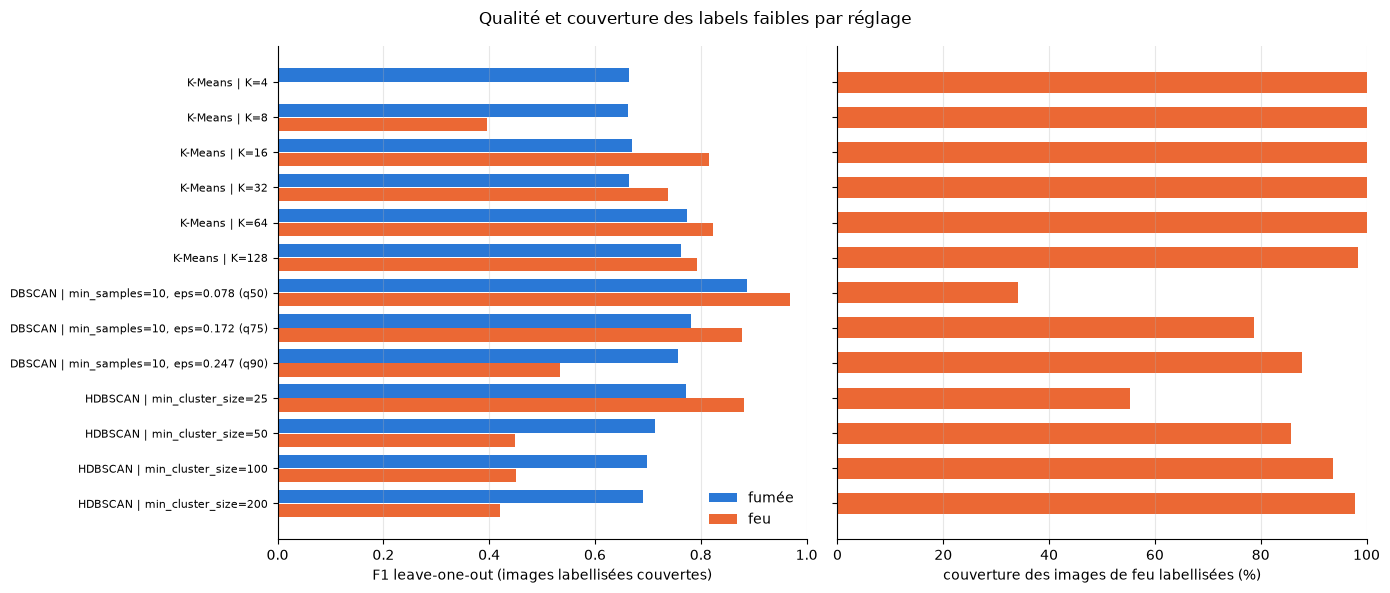

In [ ]:
# F1 et couverture des images de feu pour chaque réglage
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
labels_y = comparison["methode"] + " | " + comparison["parametres"]
y_pos = np.arange(len(comparison))
axes[0].barh(y_pos - 0.2, comparison["has_smoke_f1"], height=0.38, color="#2a78d6", label="fumée")
axes[0].barh(y_pos + 0.2, comparison["has_fire_f1"], height=0.38, color="#eb6834", label="feu")
axes[0].set_xlabel("F1 leave-one-out (images labellisées couvertes)")
axes[0].set_xlim(0, 1)
axes[0].legend(frameon=False, loc="lower right")
axes[1].barh(y_pos, comparison["couverture feu (%)"], height=0.6, color="#eb6834")
axes[1].set_xlabel("couverture des images de feu labellisées (%)")
axes[1].set_xlim(0, 100)
axes[0].set_yticks(y_pos, labels_y, fontsize=8)
axes[0].invert_yaxis()
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Qualité et couverture des labels faibles par réglage")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "clustering_comparison.png", dpi=100)
plt.show()

### Comparaison des candidats

Meilleurs compromis de chaque méthode, plus les trois réglages DBSCAN pour montrer l'effet d'eps.
Toutes les valeurs sont calculées sur les **images labellisées uniquement** :
- **couverture** : part des images qui reçoivent un label faible (le reste est exclu de l'entraînement) ;
- **F1** : qualité des labels faibles sur les images couvertes (leave-one-out).

In [ ]:
candidates = [("K-Means", "K=4"), ("K-Means", "K=64"), ("K-Means", "K=128")]
candidates += [k for k in partitions if k[0] == "DBSCAN"]
candidates += [("HDBSCAN", "min_cluster_size=25")]
cols = ["n_clusters", "bruit (%)", "couverture (%)", "couverture feu (%)", "has_smoke_f1", "has_fire_f1", "f1_mean"]
display(comparison.set_index(["methode", "parametres"]).loc[candidates, cols].round(3))

# Taille du plus gros cluster : un cluster géant mélange les catégories et fausse le vote majoritaire
biggest = {k: 100 * np.bincount(partitions[k][partitions[k] != -1]).max() / len(df_train) for k in candidates}
display(pd.Series(biggest, name="plus gros cluster (% du train)").round(1).to_frame())

n_clusters  bruit (%)  \
methode parametres                                               
K-Means K=4                                       4      0.000   
        K=64                                     64      0.000   
        K=128                                   128      0.000   
DBSCAN  min_samples=10, eps=0.078 (q50)         258     43.092   
        min_samples=10, eps=0.172 (q75)         234     15.262   
        min_samples=10, eps=0.247 (q90)         159      4.857   
HDBSCAN min_cluster_size=25                     134     35.991   

                                         couverture (%)  couverture feu (%)  \
methode parametres                                                            
K-Means K=4                                     100.000             100.000   
        K=64                                     99.273             100.000   
        K=128                                    97.820              98.404   
DBSCAN  min_samples=10, eps=0.078 (q50)          47.820              34.043   
        min_samples=10, eps=0.172 (q75)          79.215              78.723   
        min_samples=10, eps=0.247 (q90)          90.262              87.766   
HDBSCAN min_cluster_size=25                      61.628              55.319   

                                         has_smoke_f1  has_fire_f1  f1_mean  
methode parametres                                                           
K-Means K=4                                     0.664        0.000    0.332  
        K=64                                    0.775        0.824    0.799  
        K=128                                   0.763        0.792    0.778  
DBSCAN  min_samples=10, eps=0.078 (q50)         0.888        0.969    0.928  
        min_samples=10, eps=0.172 (q75)         0.782        0.878    0.830  
        min_samples=10, eps=0.247 (q90)         0.756        0.534    0.645  
HDBSCAN min_cluster_size=25                     0.773        0.883    0.828

plus gros cluster (% du train)
K-Means K=4                                                        70.5
        K=64                                                        7.6
        K=128                                                       2.7
DBSCAN  min_samples=10, eps=0.078 (q50)                             2.2
        min_samples=10, eps=0.172 (q75)                             7.0
        min_samples=10, eps=0.247 (q90)                            34.9
HDBSCAN min_cluster_size=25                                         3.5

## 9. Méthode retenue et labels faibles

**Choix : K-Means, K = 64.**

Justification, à partir de la comparaison des candidats ci-dessus :
- **DBSCAN** : la qualité et la couverture évoluent en sens inverse avec eps. À petit eps (q50), les labels
  sont très bons mais près de la moitié du train est du bruit, sans label. À grand eps (q90), presque tout est
  couvert, mais un **cluster géant** (≈ 35 % du train) regroupe le nuage d'images web : le vote majoritaire
  lui attribue « pas de feu » et la plupart des feux reçoivent un label faux (F1 feu ≈ 0,53).
  Le meilleur compromis DBSCAN (q75) laisse encore ≈ 21 % du train et ≈ 21 % des images de feu sans label.
- **HDBSCAN** : même compromis, avec une couverture plus faible au meilleur F1.
- **K-Means K = 4** (un cluster par catégorie) échoue : aucun cluster n'est majoritairement « feu » (F1 feu = 0).
- **K-Means K = 64** : F1 fumée équivalent à DBSCAN q75 et F1 feu légèrement inférieur (≈ −0,05, écart
  mesuré sur ~550 images), mais **≈ 99 % du train couvert**, toutes les images de feu comprises, et pas de
  bruit (seules les images des rares clusters sans image labellisée restent sans label).
  K = 128 fait moins bien : trop peu d'images labellisées par cluster pour voter.

Pour une alerte incendie, garder **toutes** les images de feu dans l'entraînement prime sur un léger gain de
qualité des labels.

In [ ]:
selected_key = SELECTED
sel = comparison.set_index(["methode", "parametres"]).loc[selected_key]
selected_clusters = partitions[selected_key]
weak, has_vote = assign_weak_labels(selected_clusters, lab_mask, y_lab)
print(f"Méthode retenue : {selected_key[0]} ({selected_key[1]})")
print(f"Clusters : {int(sel['n_clusters'])} | bruit : {sel['bruit (%)']:.1f} % | "
      f"images avec label faible : {has_vote.mean():.1%} du train")

# Pour les images labellisées, on garde évidemment leurs vrais labels
weak[lab_mask] = y_lab
has_weak = has_vote | lab_mask
df_train["cluster"] = selected_clusters
df_train["has_weak_label"] = has_weak
df_train["weak_smoke"] = np.where(has_weak, weak[:, 0], np.nan)
df_train["weak_fire"] = np.where(has_weak, weak[:, 1], np.nan)

mlflow.log_params({"selected_method": selected_key[0], "selected_settings": selected_key[1],
                   "noise_rule": "exclude"})
mlflow.log_metrics({"selected_f1_mean_loo": sel["f1_mean"], "selected_noise_pct": sel["bruit (%)"],
                    "selected_coverage_pct": 100 * has_vote.mean()})

Méthode retenue : K-Means (K=64)
Clusters : 64 | bruit : 0.0 % | images avec label faible : 98.7% du train


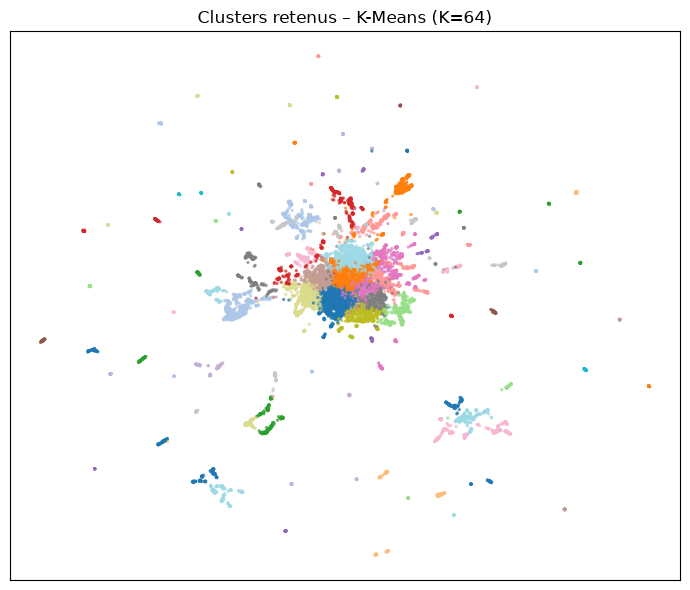

In [ ]:
# Projection 2D colorée par cluster retenu (bruit en gris)
fig, ax = plt.subplots(figsize=(7, 6))
noise = selected_clusters == -1
ax.scatter(X_umap2[noise, 0], X_umap2[noise, 1], s=2, color="lightgray", label="bruit")
ax.scatter(X_umap2[~noise, 0], X_umap2[~noise, 1], s=2, c=selected_clusters[~noise], cmap="tab20", alpha=0.6)
ax.set_title(f"Clusters retenus – {selected_key[0]} ({selected_key[1]})")
ax.set_xticks([]), ax.set_yticks([])
if noise.any():
    ax.legend(markerscale=6, frameon=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "clusters_train.png", dpi=100)
plt.show()

## 10. Qualité réelle des labels faibles

Avantage de D-Fire par rapport au P7 : les images « non labellisées » ont en réalité des labels.
On peut donc **mesurer** la couverture et la qualité des labels faibles. Cette mesure est faite **après**
le choix de la méthode et n'influence aucun paramètre.

In [ ]:
unl = ~lab_mask
covered = unl & has_vote                 # images non labellisées qui ont reçu un label faible

# Couverture par catégorie réelle et par source
display((df_train[unl].groupby("category")["has_weak_label"].mean().reindex(CATEGORY_ORDER) * 100)
        .round(1).to_frame("couverture (%)"))
display((df_train[unl].groupby("source")["has_weak_label"].mean() * 100).round(1).to_frame("couverture (%)"))

# Qualité sur les images couvertes, par tâche
quality = pd.DataFrame([
    {"tâche": task, **dict(zip(["précision", "rappel", "F1"],
     precision_recall_fscore_support(y_all[covered, j], weak[covered, j], average="binary", zero_division=0)[:3])),
     "accuracy": (y_all[covered, j] == weak[covered, j]).mean(),
     "prévalence réelle": y_all[covered, j].mean(), "prévalence faible": weak[covered, j].mean()}
    for j, task in enumerate(TASKS)
])
display(quality.round(3))

for _, q in quality.iterrows():
    task = q["tâche"].replace("has_", "")
    mlflow.log_metrics({f"weak_{task}_precision": q["précision"], f"weak_{task}_recall": q["rappel"],
                        f"weak_{task}_f1": q["F1"], f"weak_{task}_accuracy": q["accuracy"]})
mlflow.log_metric("weak_coverage_unlabeled_pct", 100 * covered.sum() / unl.sum())

# Même mesure par source : la qualité dépend-elle de l'origine des images ?
by_source = []
for src, g in df_train[covered].groupby("source"):
    idx = g.index.to_numpy()
    for j, task in enumerate(TASKS):
        f1 = precision_recall_fscore_support(y_all[idx, j], weak[idx, j], average="binary", zero_division=0)[2]
        by_source.append({"source": src, "tâche": task, "F1": f1})
display(pd.DataFrame(by_source).pivot(index="source", columns="tâche", values="F1").round(3))

,couverture (%)
category,
smoke_only,99.6
fire_only,100.0
fire_and_smoke,100.0
none,97.3


,couverture (%)
source,
AoF,98.4
PublicDataset,100.0
WEB,98.7


,tâche,précision,rappel,F1,accuracy,prévalence réelle,prévalence faible
0,has_smoke,0.713,0.725,0.719,0.719,0.496,0.505
1,has_fire,0.819,0.720,0.767,0.879,0.277,0.243


tâche,has_fire,has_smoke
source,,
AoF,0.883,0.571
PublicDataset,0.760,0.665
WEB,0.737,0.785


In [ ]:
# Labels faibles traduits en 4 catégories (lignes : réel, colonnes : faible), images couvertes
def to_category(smoke, fire):
    return np.select([(smoke == 1) & (fire == 1), fire == 1, smoke == 1],
                     ["fire_and_smoke", "fire_only", "smoke_only"], "none")


weak_cat = to_category(weak[covered, 0], weak[covered, 1])
display(pd.crosstab(df_train.loc[covered, "category"], weak_cat, rownames=["réel"], colnames=["faible"])
          .reindex(index=CATEGORY_ORDER, columns=CATEGORY_ORDER, fill_value=0))
print(f"Accuracy sur les 4 catégories : {(df_train.loc[covered, 'category'].to_numpy() == weak_cat).mean():.3f}")

faible,smoke_only,fire_only,fire_and_smoke,none
réel,,,,
smoke_only,1772,0,390,1382
fire_only,60,0,581,71
fire_and_smoke,490,0,1993,378
none,1054,0,179,4562


Accuracy sur les 4 catégories : 0.645


## 11. Sauvegarde

In [ ]:
out = meta[["image_id", "final_split", "test_clean", "source", "category", "has_smoke", "has_fire"]].copy()
out = out.merge(df_train[["image_id", "is_labeled", "cluster", "has_weak_label", "weak_smoke", "weak_fire"]],
                on="image_id", how="left")
out.to_csv(WEAK_LABELS_PATH, index=False)
comparison.to_csv(CLUSTERING_COMPARISON_PATH, index=False)
print(f"Labels faibles : {WEAK_LABELS_PATH.name} – {out.shape} (colonnes weak_* renseignées pour le train)")
print(f"Comparaison    : {CLUSTERING_COMPARISON_PATH.name} – {comparison.shape}")

# Artefacts MLflow : tableau de comparaison et figures, puis fermeture du run parent
mlflow.log_artifact(str(CLUSTERING_COMPARISON_PATH))
for fig_name in ["pca_variance.png", "umap_train.png", "clustering_comparison.png", "clusters_train.png"]:
    mlflow.log_artifact(str(RESULTS_DIR / fig_name), artifact_path="figures")
mlflow.end_run()
print(f"Run MLflow terminé : {parent_run.info.run_id}")

Labels faibles : weak_labels.csv – (21527, 12) (colonnes weak_* renseignées pour le train)
Comparaison    : clustering_comparison.csv – (13, 15)
Run MLflow terminé : 246bb06b74c146db9b632c21e14b260b


## 12. Conclusions

_Chiffres issus de l'exécution du 13/11/2026._

**Faible étiquetage simulé**
- **688 images labellisées** (5,0 % du train) et 13 085 non labellisées, proportions des catégories respectées.

**Réduction de dimension**
- Variance très étalée : 150 composantes ne gardent que **56,9 %** de la variance, 200 composantes **61,7 %**.
  PCA retenue à **950 composantes (90,1 %)**, puis UMAP 10D (`n_neighbors=30`, `min_dist=0`).

**Structure des données**
- La projection 2D montre surtout la **source** : îlots `AoF` (vraisemblablement une scène / caméra fixe chacun, d'après la figure), nuage central `WEB`
  où les catégories se mélangent. **ARI ≈ 0 pour toutes les méthodes** (−0,04 à 0,08) : les clusters
  regroupent des **scènes**, pas des catégories fumée / feu.

**Comparaison** (images labellisées uniquement)
- **K-Means K = 4** (un cluster par catégorie) : F1 feu = 0, un cluster contient 70,5 % du train.
- **DBSCAN** : qualité et couverture s'opposent. q50 : F1 0,928 mais 47,8 % de couverture (34 % des feux) ;
  q75 : F1 0,830, couverture 79,2 % ; q90 : couverture 90,3 % mais un cluster géant (34,9 % du train),
  F1 feu 0,534.
- **HDBSCAN** (`min_cluster_size=25`) : F1 0,828, couverture 61,6 %.
- **K-Means K = 64** : F1 fumée 0,775, feu 0,824, couverture 99,3 % (100 % des feux) → **retenu**.
  K = 128 : F1 0,778, en baisse.

**Qualité réelle des labels faibles** (images non labellisées, mesurée après le choix)
- **98,7 % du train** reçoit un label faible ; 100 % des images `fire_only` et `fire_and_smoke` sont couvertes.
- Fumée : F1 **0,719** (accuracy 0,719) ; feu : F1 **0,767** (accuracy 0,879, rappel 0,720).
  Ces valeurs sont **inférieures** à l'estimation leave-one-out (0,775 / 0,824) : l'estimation sur 688 images
  était optimiste.
- **Aucune image n'est labellisée `fire_only`** : aucun cluster n'a une majorité « feu sans fumée ». Les
  images `fire_only` reçoivent surtout `fire_and_smoke` (581 / 712) : le feu est bien capté, la fumée ajoutée à tort.
- Par source, le F1 fumée est faible sur `AoF` (0,571) ; le F1 feu va de 0,737 (`WEB`) à 0,883 (`AoF`).

**Suite – apprentissage semi-supervisé (MLP puis CNN)** : comparer le modèle A (688 images labellisées seules)
aux modèles B (+ labels faibles) et C (+ augmentation), évalués sur val puis sur test complet et test propre.
Avec ~28 % d'erreurs sur la fumée et ~12 % sur le feu dans les labels faibles, le gain de B / C n'est pas
garanti : c'est précisément ce que la comparaison doit mesurer.